# DBMS Fundamentals: Introduction and Architecture

> **Who is this for:** beginners who have finished [Python basics](../../01_Python/01_basic.ipynb) and want to understand *what a database management system actually is* — and university students revising the first chapters of a DBMS course for exams or interviews.
>
> **What you will learn:**
> - The difference between **data** and **information**, and why plain files break down as data grows (you will *watch* them break, using CSV files vs. SQLite)
> - Why we need a **DBMS**, what it gives you and what it costs
> - Core concepts: **schema vs. instance**, **data models**, the **three-schema (ANSI/SPARC) architecture**, **data independence** and **levels of abstraction**
> - The four DBMS languages: **DDL, DML, DCL, TCL**
> - The inside of a DBMS: **query processor, storage manager, buffer manager, transaction manager** (you will build a tiny LRU buffer manager)
> - **1-, 2- and 3-tier** architectures; centralized, client-server, distributed and cloud databases
> - Who uses a DBMS (DBA, designers, end users, programmers) and through which interfaces
> - Database objects: tables, views, indexes, sequences, triggers, stored procedures, synonyms
> - The **impedance mismatch** between SQL and programming languages, and how ORMs address it
> - Which DBMSs are popular today and what they are used for
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb). Helpful but not required: [pandas](../../02_Data_Analysis/03_pandas.ipynb).
>
> **Time needed:** about 90 minutes.
>
> **Runs on:** CPU, no API key, no internet. Uses only the Python standard library (`sqlite3`, `csv`, `json`), `pandas` and `matplotlib`.
>
> **Optional track:** this notebook is part of the *university-level fundamentals track*; recommended for BS/MS AI students and interview prep. The practical, hands-on SQL lives in [SQL Fundamentals](../01_sql/01_sql_fundamentals.ipynb); here we focus on the theory behind it (Silberschatz/Korth/Sudarshan ch. 1, Elmasri/Navathe ch. 1–2).

## Explained simply

A **database** is an organised store of related facts, and a **database management system (DBMS)** is the program that keeps those facts safe, tidy and easy to ask questions about. Without one, every office keeps its own files, like a school where the office and the library each keep their own copy of your address: when you move, one copy gets forgotten and the two disagree. A DBMS stores each fact once, checks rules (no negative ages), lets many people use the data at the same time without overwriting each other, and survives crashes. It works like a library with a librarian: you say what you want ("all books by this author") and the librarian works out where to find it, so you never search the shelves yourself. You will also look inside a DBMS (one part understands your question, another fetches pages from disk) and at the different ways it can be set up. Almost every app you use, and every AI system that stores training data or user history, sits on top of one.

**Tiny example.** Account A holds 50,000 and account B holds 20,000, so together they hold 70,000. You move 10,000 from A to B: step 1 takes 10,000 from A, step 2 adds 10,000 to B. With plain files, a crash after step 1 leaves A = 40,000 and B = 20,000: the total is now 60,000 and 10,000 has vanished. A DBMS wraps both steps in one **transaction**, so after the crash it rolls back to A = 50,000 and B = 20,000, and the total is still 70,000.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Database / DBMS | an organised store of facts plus the program that guards it | banking, shopping and social-media apps; storage for ML training data |
| Transaction | a group of changes that happens completely or not at all | a bank transfer, booking a seat, an AI agent paying for a flight |
| Data independence | change how data is stored without breaking the programs that use it | adding an index to speed up a query; moving data to new storage without rewriting model-training code |

## 0. Setup

> 💡 **In plain English:** we open a small database that lives in memory, so nothing is installed and nothing is left behind.

Everything runs on an **in-memory SQLite** database (`sqlite3.connect(":memory:")`) or in a temporary folder that is deleted at the end. SQLite is a real, full DBMS that ships inside Python — it is the most widely deployed database engine in the world (it is inside every phone and browser).

In [1]:
import sqlite3                     # a complete relational DBMS, built into Python
import csv, json, os, shutil       # for the "file-processing system" demo
import tempfile                    # temporary folder, deleted at the end
from collections import OrderedDict
import pandas as pd                # to display relations (tables) nicely
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

pd.set_option("display.width", 120)
WORKDIR = tempfile.mkdtemp(prefix="dbms_intro_")    # all files go here
print("SQLite library version:", sqlite3.sqlite_version)

def show(conn, sql, params=()):
    """Run a query and return the result as a pandas DataFrame (a relation)."""
    return pd.read_sql_query(sql, conn, params=params)

SQLite library version: 3.45.1


## 1. Data vs. Information

> 💡 **In plain English:** data is raw facts like `31, 33, 29`; information is what those facts tell you, like "the average is 31 °C".

**Analogy.** A shoebox full of supermarket receipts is *data*. "I spent 23% of my money on snacks this month" is *information*.

- **Data** = raw, unorganised facts that can be recorded (numbers, text, dates, images). On their own they have no meaning: `72`, `"2026-10-01"`, `"Lahore"`.
- **Information** = data that has been **processed, organised and put in context** so that it is meaningful and useful for a decision: *"the average temperature in Lahore in October was 31 °C"*.
- A **database** is a collection of *related* data; a **database management system (DBMS)** is the software that defines, stores, manipulates and protects that database, and helps turn data into information through **queries**.

| | Data | Information |
|---|---|---|
| Nature | raw facts | processed, interpreted facts |
| Meaning | none by itself | has context and purpose |
| Example | `31, 33, 29, 30` | "average = 30.75 °C, rising trend" |
| Depends on | nothing | data |

In [2]:
# Raw DATA: individual sensor readings (city, day, temperature in °C)
readings = [("Lahore", 1, 31), ("Lahore", 2, 33), ("Karachi", 1, 28),
            ("Lahore", 3, 29), ("Karachi", 2, 30), ("Karachi", 3, 29)]

# Processing turns data into INFORMATION: an average per city
totals = {}                                   # city -> [sum, count]
for city, day, temp in readings:
    s = totals.setdefault(city, [0, 0])
    s[0] += temp                              # running sum
    s[1] += 1                                 # running count
info = {city: round(s / n, 2) for city, (s, n) in totals.items()}
print("Data       :", readings)
print("Information:", info)

# The same processing as ONE declarative query in a DBMS
conn = sqlite3.connect(":memory:")
conn.execute("CREATE TABLE reading(city TEXT, day INT, temp REAL)")
conn.executemany("INSERT INTO reading VALUES (?,?,?)", readings)
q = show(conn, "SELECT city, ROUND(AVG(temp),2) AS avg_temp FROM reading GROUP BY city ORDER BY city")
print(q)
assert dict(zip(q.city, q.avg_temp)) == info   # both routes give the same information
conn.close()

Data       : [('Lahore', 1, 31), ('Lahore', 2, 33), ('Karachi', 1, 28), ('Lahore', 3, 29), ('Karachi', 2, 30), ('Karachi', 3, 29)]
Information: {'Lahore': 31.0, 'Karachi': 29.0}
      city  avg_temp
0  Karachi      29.0
1   Lahore      31.0


**What just happened?** We wrote a loop that *says how* to compute the averages (procedural). The DBMS version *says what* we want (`AVG ... GROUP BY city`) and lets the system work out how. That declarative style is one of the biggest gifts of a DBMS.

## 2. File-Processing Systems and Their Problems

> 💡 **In plain English:** keeping data in separate plain files leads to copies that disagree, broken rules, money lost in crashes and people overwriting each other; we watch each problem happen and see a database fix it.

Before DBMSs (1960s) — and still today in many small offices — each application kept its **own files**: the registrar's program had `students.csv`, the accounts program had its own `fees.csv`, the library had a JSON file, and so on. This is a **file-processing system**: permanent records stored in OS files, with application programs written to read and update them.

Silberschatz/Korth/Sudarshan list the classic disadvantages. We will **demonstrate each one** with real CSV files in a temporary folder, then show how SQLite fixes it.

| # | Problem | One-line meaning |
|---|---|---|
| 1 | **Data redundancy** | the same fact is stored in several files |
| 2 | **Data inconsistency** | the copies disagree after an update |
| 3 | **Difficulty accessing data** | every new question needs a new program |
| 4 | **Data isolation** | data scattered in different files and formats |
| 5 | **Integrity problems** | rules (e.g. "age ≥ 16") are buried in code, easy to bypass |
| 6 | **Atomicity problems** | a crash halfway leaves data half-updated |
| 7 | **Concurrent-access anomalies** | two users overwrite each other's changes |
| 8 | **Security problems** | hard to let a user see only *part* of a file |

### 2.1 Redundancy and inconsistency

The **registrar** and the **accounts office** each store the student's address in their own file. When the student moves, only one office is told.

In [3]:
reg_path = os.path.join(WORKDIR, "registrar_students.csv")   # file owned by the registrar
acc_path = os.path.join(WORKDIR, "accounts_fees.csv")        # file owned by accounts

# Both files store the student's ADDRESS -> redundancy
with open(reg_path, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["sid", "name", "address", "age"])
    w.writerow([1, "Ayesha", "12 Mall Road", 20])
    w.writerow([2, "Bilal", "7 Canal View", 21])
with open(acc_path, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["sid", "name", "address", "fee_due"])
    w.writerow([1, "Ayesha", "12 Mall Road", 50000])
    w.writerow([2, "Bilal", "7 Canal View", 45000])

def update_csv(path, sid, column, value):
    """Rewrite a whole CSV file just to change one cell (what file programs do)."""
    with open(path, newline="") as f:
        rows = list(csv.DictReader(f))
    for r in rows:
        if r["sid"] == str(sid):
            r[column] = value
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=rows[0].keys())
        w.writeheader(); w.writerows(rows)

# Ayesha moves house; ONLY the registrar's program is updated
update_csv(reg_path, 1, "address", "99 New Town")

reg = pd.read_csv(reg_path); acc = pd.read_csv(acc_path)
both = reg[["sid", "address"]].merge(acc[["sid", "address"]], on="sid", suffixes=("_registrar", "_accounts"))
print(both)
print("\nInconsistent rows:", int((both.address_registrar != both.address_accounts).sum()))

   sid address_registrar address_accounts
0    1       99 New Town     12 Mall Road
1    2      7 Canal View     7 Canal View

Inconsistent rows: 1


In [4]:
# DBMS fix: store the address ONCE; every department refers to the student by key
db = sqlite3.connect(":memory:")
db.executescript("""
CREATE TABLE student(sid INTEGER PRIMARY KEY, name TEXT NOT NULL, address TEXT, age INT);
CREATE TABLE fee(sid INTEGER REFERENCES student(sid), fee_due INT);
INSERT INTO student VALUES (1,'Ayesha','12 Mall Road',20), (2,'Bilal','7 Canal View',21);
INSERT INTO fee VALUES (1,50000), (2,45000);
""")
db.execute("UPDATE student SET address='99 New Town' WHERE sid=1")   # one update, one place
print(show(db, "SELECT s.sid, s.name, s.address, f.fee_due FROM student s JOIN fee f USING(sid)"))

   sid    name       address  fee_due
0    1  Ayesha   99 New Town    50000
1    2   Bilal  7 Canal View    45000


**What just happened?** In the file system the address existed twice, so a single real-world change needed two file updates — one was forgotten and the files now **contradict** each other. In the database the address is stored once and the accounts table refers to it through the key `sid`; there is nothing to get out of sync. (Removing redundancy systematically is called **normalization**; see [Relational DB Design](../../22_ML_System_Design/03_relational_db_design.ipynb).)

### 2.2 Difficulty accessing data and data isolation

A new question — *"which students over 20 owe more than 40 000?"* — needs a **new program** in a file system, especially when the data sits in **different formats** (CSV for the registrar, JSON for the library). In a DBMS it is one query.

In [5]:
lib_path = os.path.join(WORKDIR, "library_loans.json")       # a THIRD format: JSON
json.dump([{"student": 1, "book": "Database System Concepts"},
           {"student": 1, "book": "Fundamentals of Database Systems"},
           {"student": 2, "book": "Clean Code"}], open(lib_path, "w"))

# --- File-system way: hand-written program that parses two formats and joins them itself
def students_with_loans_over_age(min_age):
    ages = {}
    with open(reg_path, newline="") as f:                     # parse CSV
        for r in csv.DictReader(f):
            ages[int(r["sid"])] = int(r["age"])
    out = []
    for loan in json.load(open(lib_path)):                    # parse JSON
        if ages.get(loan["student"], 0) > min_age:            # manual join + filter
            out.append((loan["student"], loan["book"]))
    return sorted(out)
print("Program result:", students_with_loans_over_age(20))

# --- DBMS way: all data in one integrated database, one declarative query
db.execute("CREATE TABLE loan(sid INT REFERENCES student(sid), book TEXT)")
db.executemany("INSERT INTO loan VALUES (?,?)", [(d["student"], d["book"]) for d in json.load(open(lib_path))])
res = db.execute("SELECT l.sid, l.book FROM loan l JOIN student s USING(sid) WHERE s.age > 20 ORDER BY 1,2").fetchall()
print("Query result  :", res)
assert res == students_with_loans_over_age(20)

Program result: [(2, 'Clean Code')]
Query result  : [(2, 'Clean Code')]


### 2.3 Integrity problems

**Integrity constraints** are rules every valid database state must satisfy ("age is between 16 and 100", "every fee row belongs to an existing student"). In a file system these rules live inside *each* program, so any program (or a person with a text editor) can bypass them. A DBMS stores the rule **once, in the schema**, and enforces it for everybody.

In [6]:
# File system: nothing stops a bad row
with open(reg_path, "a", newline="") as f:
    csv.writer(f).writerow([3, "Chen", "1 Lake Rd", -5])        # age -5 accepted silently
print(pd.read_csv(reg_path).tail(2))

# DBMS: the rule is part of the schema (CHECK constraint)
db.execute("CREATE TABLE student2(sid INTEGER PRIMARY KEY, name TEXT NOT NULL, age INT CHECK(age BETWEEN 16 AND 100))")
try:
    db.execute("INSERT INTO student2 VALUES (3,'Chen',-5)")
except sqlite3.IntegrityError as e:
    print("\nDBMS rejected the row ->", e)

   sid   name       address  age
1    2  Bilal  7 Canal View   21
2    3   Chen     1 Lake Rd   -5

DBMS rejected the row -> CHECK constraint failed: age BETWEEN 16 AND 100


### 2.4 Atomicity problems

**Atomicity** means a group of changes happens **all or nothing**. Classic example: transfer 10 000 from account A to B = *debit A* then *credit B*. If the program crashes in between, the money vanishes. We simulate the crash with an exception.

In [7]:
bank_csv = os.path.join(WORKDIR, "bank.csv")
def write_bank(rows):
    with open(bank_csv, "w", newline="") as f:
        csv.writer(f).writerows([["acct", "balance"]] + rows)
def read_bank():
    with open(bank_csv, newline="") as f:
        return {r["acct"]: int(r["balance"]) for r in csv.DictReader(f)}

write_bank([["A", 50000], ["B", 20000]])
before = sum(read_bank().values())

def transfer_file(src, dst, amount, crash=False):
    bal = read_bank()
    bal[src] -= amount
    write_bank([[k, v] for k, v in bal.items()])          # step 1 written to disk
    if crash:
        raise RuntimeError("power failure!")              # crash between the two steps
    bal[dst] += amount
    write_bank([[k, v] for k, v in bal.items()])          # step 2

try:
    transfer_file("A", "B", 10000, crash=True)
except RuntimeError as e:
    print("Crash:", e)
after = sum(read_bank().values())
print("File system: total money before =", before, " after =", after, " -> lost", before - after)

Crash: power failure!
File system: total money before = 70000  after = 60000  -> lost 10000


In [8]:
bank = sqlite3.connect(":memory:", isolation_level=None)   # autocommit mode; we control transactions
bank.executescript("CREATE TABLE account(acct TEXT PRIMARY KEY, balance INT CHECK(balance >= 0));"
                   "INSERT INTO account VALUES ('A',50000),('B',20000);")

def transfer_db(src, dst, amount, crash=False):
    bank.execute("BEGIN")                                  # start a transaction
    try:
        bank.execute("UPDATE account SET balance = balance - ? WHERE acct=?", (amount, src))
        if crash:
            raise RuntimeError("power failure!")
        bank.execute("UPDATE account SET balance = balance + ? WHERE acct=?", (amount, dst))
        bank.execute("COMMIT")                             # make both changes permanent together
    except Exception as e:
        bank.execute("ROLLBACK")                           # undo everything since BEGIN
        print("Rolled back because:", e)

transfer_db("A", "B", 10000, crash=True)
print(show(bank, "SELECT * FROM account"))
print("Total:", bank.execute("SELECT SUM(balance) FROM account").fetchone()[0], "(unchanged: 70000)")
transfer_db("A", "B", 10000)                               # a normal, successful transfer
print(show(bank, "SELECT * FROM account"))

Rolled back because: power failure!
  acct  balance
0    A    50000
1    B    20000
Total: 70000 (unchanged: 70000)
  acct  balance
0    A    40000
1    B    30000


**What just happened?** The file "system" persisted the debit and lost 10 000 forever. The DBMS wrapped both updates in a **transaction**; on failure `ROLLBACK` restored the earlier state, so the total stays 70 000. (Real DBMSs also survive genuine power cuts using a **log** — write-ahead logging — which the recovery manager replays after restart.)

### 2.5 Concurrent-access anomalies (the *lost update*)

Two clerks withdraw money from the same account at the same moment. Each program **reads** the balance, **subtracts**, and **writes** it back. If the steps interleave, one withdrawal disappears.

In [9]:
write_bank([["A", 50000], ["B", 30000]])

# Interleaved schedule (time flows downwards):
#   clerk 1: read A=50000
#   clerk 2: read A=50000
#   clerk 1: write A=50000-5000
#   clerk 2: write A=50000-7000   <- overwrites clerk 1's write
c1 = read_bank()                       # clerk 1 reads
c2 = read_bank()                       # clerk 2 reads the SAME old value
c1["A"] -= 5000; write_bank([[k, v] for k, v in c1.items()])
c2["A"] -= 7000; write_bank([[k, v] for k, v in c2.items()])
print("Expected A = 50000 - 5000 - 7000 = 38000; file says A =", read_bank()["A"], "-> lost update of 5000")

Expected A = 50000 - 5000 - 7000 = 38000; file says A = 43000 -> lost update of 5000


In [10]:
# DBMS fix: concurrency control. SQLite locks the database file for writers.
dbfile = os.path.join(WORKDIR, "bank.db")
setup = sqlite3.connect(dbfile)
setup.executescript("DROP TABLE IF EXISTS account; CREATE TABLE account(acct TEXT PRIMARY KEY, balance INT);"
                    "INSERT INTO account VALUES ('A',50000);")
setup.close()

clerk1 = sqlite3.connect(dbfile, timeout=0, isolation_level=None)   # timeout=0: don't wait for locks
clerk2 = sqlite3.connect(dbfile, timeout=0, isolation_level=None)

clerk1.execute("BEGIN IMMEDIATE")                         # clerk 1 takes the write lock
bal = clerk1.execute("SELECT balance FROM account WHERE acct='A'").fetchone()[0]
try:
    clerk2.execute("BEGIN IMMEDIATE")                     # clerk 2 must wait: lock is held
except sqlite3.OperationalError as e:
    print("Clerk 2 is blocked ->", e)
clerk1.execute("UPDATE account SET balance=? WHERE acct='A'", (bal - 5000,))
clerk1.execute("COMMIT")                                  # releases the lock

clerk2.execute("BEGIN IMMEDIATE")                         # now clerk 2 reads the NEW value
bal = clerk2.execute("SELECT balance FROM account WHERE acct='A'").fetchone()[0]
clerk2.execute("UPDATE account SET balance=? WHERE acct='A'", (bal - 7000,))
clerk2.execute("COMMIT")
final = clerk2.execute("SELECT balance FROM account").fetchone()[0]
print("Final balance:", final)
assert final == 38000
clerk1.close(); clerk2.close()

Clerk 2 is blocked -> database is locked


Final balance: 38000


**What just happened?** The DBMS's **concurrency-control manager** forced the two transactions to take turns on the write lock, so the second clerk saw 45 000, not the stale 50 000. Real servers (PostgreSQL, Oracle, SQL Server) use finer-grained row locks and multi-version concurrency control (MVCC) so many users can work in parallel. The equivalent simpler expression is `UPDATE account SET balance = balance - 7000`, which reads and writes in one atomic statement.

### 2.6 Security problems

The accounts clerk should see fees but not home addresses. With a file you either get the whole file or nothing. A DBMS offers **views** plus **authorization** (`GRANT`/`REVOKE`) so a user sees only certain rows and columns. SQLite is an embedded, single-user library and has no user accounts, so `GRANT` is not available there; we show the view part.

In [11]:
db.execute("CREATE VIEW accounts_view AS SELECT s.sid, s.name, f.fee_due FROM student s JOIN fee f USING(sid)")
print(show(db, "SELECT * FROM accounts_view"))      # no address column is exposed
try:
    db.execute("GRANT SELECT ON accounts_view TO accounts_clerk")   # server DBMSs support this
except sqlite3.OperationalError as e:
    print("\nSQLite has no users/GRANT (embedded DBMS):", e)

   sid    name  fee_due
0    1  Ayesha    50000
1    2   Bilal    45000

SQLite has no users/GRANT (embedded DBMS): near "GRANT": syntax error


| Problem | File-processing system | DBMS solution |
|---|---|---|
| Redundancy / inconsistency | each app keeps its own copy | single integrated database, normalization, keys |
| Difficult access | new program per question | declarative query language (SQL) |
| Data isolation | many files, many formats | one data model, one catalog |
| Integrity | rules hidden in code | constraints in schema (`CHECK`, `FOREIGN KEY`, …) |
| Atomicity | partial updates after crash | transactions + logging + recovery |
| Concurrency | lost updates | locking / MVCC, isolation levels |
| Security | all-or-nothing file access | users, roles, `GRANT`, views |

> ⚠️ **Common mistake:** saying "a DBMS removes *all* redundancy". It **controls** redundancy. Some redundancy is added on purpose (indexes, replicas, caches, denormalised reporting tables) — but the DBMS keeps it consistent for you.

## 3. Why a DBMS? Advantages and Costs

> 💡 **In plain English:** a DBMS costs money, skills and some speed, but in return keeps data correct, shared, safe and easy to query.

A **database management system (DBMS)** is a general-purpose software system that lets users **define** (specify types, structures, constraints), **construct** (store the data), **manipulate** (query, update) and **share** databases among many users and programs, while **protecting** them against crashes and unauthorized access (Elmasri/Navathe's definition).

| Advantages | Costs / disadvantages |
|---|---|
| Controlled redundancy and consistency | Software licences (for commercial DBMSs) and hardware |
| Data sharing among many users and apps | Need for trained staff (DBA, designers) |
| Integrity constraints enforced centrally | Overhead: security, concurrency, recovery cost CPU and I/O |
| Security and authorization | Complexity: a DBMS is a large, complex system |
| Backup and recovery | Single point of failure if not replicated |
| Concurrency control | Overkill for tiny, single-user, fixed-query problems |
| Declarative querying + optimization | Migration / conversion cost from old file systems |
| Data independence (programs survive schema change) | Vendor lock-in with proprietary features |
| Standards (SQL), faster development | |

**When is a DBMS *not* worth it?** A single program with a few simple, well-known operations on small data (e.g. an embedded thermostat config, a one-off script). Even then, SQLite is so cheap that it is often still the right answer — its website literally says "SQLite competes with `fopen()`".

## 4. Database System Concepts

> 💡 **In plain English:** a database has a fixed design (the schema) and changing contents (the instance), and it hides storage details in layers so programs keep working when things change underneath.

### 4.1 Schema vs. instance

**Analogy:** the schema is the *form* with labelled boxes; the instance is the *pile of filled-in forms* today.

- **Schema (intension)**: the *description* of the database — relation names, attributes, types, constraints. Designed once, changes rarely. Stored in the **data dictionary / system catalog** (metadata = "data about data").
- **Instance (extension, database state)**: the *actual data* stored at one moment in time. Changes with every insert, update or delete.

In [12]:
uni = sqlite3.connect(":memory:")
uni.executescript("""
CREATE TABLE department(dept_name TEXT PRIMARY KEY, building TEXT, budget REAL);
CREATE TABLE instructor(id TEXT PRIMARY KEY, name TEXT NOT NULL,
                        dept_name TEXT REFERENCES department(dept_name), salary REAL CHECK(salary > 0));
""")
# The SCHEMA lives in SQLite's system catalog table `sqlite_master` (data about data)
schema_t0 = show(uni, "SELECT type, name, sql FROM sqlite_master")
print(schema_t0.to_string())

print("\nInstance at time t0 (empty):", uni.execute("SELECT COUNT(*) FROM instructor").fetchone()[0], "rows")
uni.executemany("INSERT INTO department VALUES (?,?,?)",
                [("Comp. Sci.", "Taylor", 100000), ("Physics", "Watson", 70000), ("Biology", "Watson", 90000)])
uni.executemany("INSERT INTO instructor VALUES (?,?,?,?)",
                [("10101", "Srinivasan", "Comp. Sci.", 65000), ("12121", "Wu", "Physics", 90000),
                 ("15151", "Mozart", "Biology", 40000), ("22222", "Einstein", "Physics", 95000)])
print("Instance at time t1:")
print(show(uni, "SELECT * FROM instructor"))
schema_t1 = show(uni, "SELECT type, name, sql FROM sqlite_master")
print("Schema unchanged by the inserts?", schema_t0.equals(schema_t1))
assert schema_t0.equals(schema_t1)

    type                           name                                                                                                                                                                        sql
0  table                     department                                                                                            CREATE TABLE department(dept_name TEXT PRIMARY KEY, building TEXT, budget REAL)
1  index  sqlite_autoindex_department_1                                                                                                                                                                       None
2  table                     instructor  CREATE TABLE instructor(id TEXT PRIMARY KEY, name TEXT NOT NULL,\n                        dept_name TEXT REFERENCES department(dept_name), salary REAL CHECK(salary > 0))
3  index  sqlite_autoindex_instructor_1                                                                                                                     

### 4.2 Data models

A **data model** is a collection of concepts for describing data, relationships, semantics (meaning) and constraints. The same facts — *Comp. Sci. department has instructors Srinivasan and Katz; Srinivasan teaches DB and AI* — look like this in each model:

| Model | Era | Structure | Navigation | Examples |
|---|---|---|---|---|
| **Hierarchical** | 1960s | tree of parent→child records (each child has 1 parent) | follow pointers from the root | IBM IMS, Windows Registry, XML |
| **Network** (CODASYL) | late 1960s–70s | graph of records and *sets* (a child can have many parents) | follow pointers record by record | IDMS, IDS |
| **Relational** | 1970 (Codd) → today | tables of rows; links through **values** (keys) | declarative queries (SQL) | PostgreSQL, MySQL, Oracle, SQLite |
| **Object-oriented / object-relational** | 1980s–90s | objects with identity, classes, inheritance, methods | object references | db4o, ObjectDB; PostgreSQL user types |
| **Document / NoSQL** (also key-value, wide-column, graph) | 2000s → today | JSON-like documents, key→value pairs, column families, property graphs | by key, by document query, by graph traversal | MongoDB, Redis, Cassandra, Neo4j |
| (ER model) | 1976 (Chen) | entities + relationships | — it is a *conceptual design* model | next notebook |

In [13]:
# ---- Hierarchical: a tree. Each record has exactly ONE parent.
hierarchical = {"Comp. Sci.": {"Srinivasan": ["DB", "AI"], "Katz": ["AI"]}}

# ---- Network: records + links; a course record can be owned by SEVERAL instructors (many parents)
network_links = [("Comp. Sci.", "Srinivasan"), ("Comp. Sci.", "Katz"),
                 ("Srinivasan", "DB"), ("Srinivasan", "AI"), ("Katz", "AI")]

# ---- Relational: flat tables; relationships are expressed by matching VALUES
rel_instructor = pd.DataFrame({"name": ["Srinivasan", "Katz"], "dept": ["Comp. Sci.", "Comp. Sci."]})
rel_teaches = pd.DataFrame({"name": ["Srinivasan", "Srinivasan", "Katz"], "course": ["DB", "AI", "AI"]})

# ---- Object-oriented: objects with identity, attributes and methods
class Instructor:
    def __init__(self, name): self.name, self.courses = name, []
    def teaches(self, c): self.courses.append(c)        # behaviour lives with the data
s = Instructor("Srinivasan"); s.teaches("DB"); s.teaches("AI")

# ---- Document (NoSQL): one self-contained JSON document per department
document = {"_id": "Comp. Sci.", "instructors": [{"name": "Srinivasan", "courses": ["DB", "AI"]},
                                                 {"name": "Katz", "courses": ["AI"]}]}

# Same question in every model: "who teaches AI?"
h = sorted(i for d in hierarchical.values() for i, cs in d.items() if "AI" in cs)
n = sorted(a for a, b in network_links if b == "AI")
r = sorted(rel_teaches.loc[rel_teaches.course == "AI", "name"])
d = sorted(i["name"] for i in document["instructors"] if "AI" in i["courses"])
print(h, n, r, d)
assert h == n == r == d == ["Katz", "Srinivasan"]
print("\nRelational view of teaches:\n", rel_teaches)
print("\nDocument view:\n", json.dumps(document, indent=1))

['Katz', 'Srinivasan'] ['Katz', 'Srinivasan'] ['Katz', 'Srinivasan'] ['Katz', 'Srinivasan']

Relational view of teaches:
          name course
0  Srinivasan     DB
1  Srinivasan     AI
2        Katz     AI

Document view:
 {
 "_id": "Comp. Sci.",
 "instructors": [
  {
   "name": "Srinivasan",
   "courses": [
    "DB",
    "AI"
   ]
  },
  {
   "name": "Katz",
   "courses": [
    "AI"
   ]
  }
 ]
}


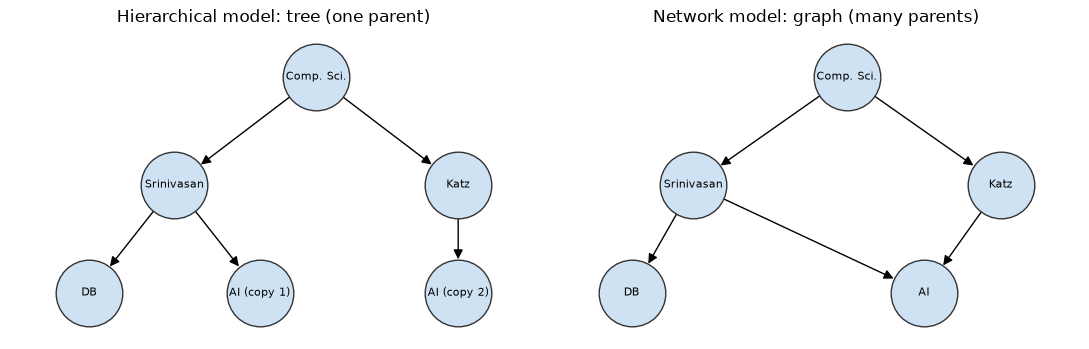

In [14]:
import networkx as nx
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
# Hierarchical: in the tree "AI" must be STORED TWICE (once under each parent) -> redundancy
T = nx.DiGraph([("Comp. Sci.", "Srinivasan"), ("Comp. Sci.", "Katz"),
                ("Srinivasan", "DB"), ("Srinivasan", "AI (copy 1)"), ("Katz", "AI (copy 2)")])
posT = {"Comp. Sci.": (0, 2), "Srinivasan": (-1, 1), "Katz": (1, 1),
        "DB": (-1.6, 0), "AI (copy 1)": (-0.4, 0), "AI (copy 2)": (1, 0)}
# Network: one "AI" record with TWO parents
N = nx.DiGraph(network_links)
posN = {"Comp. Sci.": (0, 2), "Srinivasan": (-1, 1), "Katz": (1, 1), "DB": (-1.4, 0), "AI": (0.5, 0)}
for ax, G, pos, title in [(axes[0], T, posT, "Hierarchical model: tree (one parent)"),
                          (axes[1], N, posN, "Network model: graph (many parents)")]:
    nx.draw_networkx(G, pos, ax=ax, node_color="#cfe2f3", node_size=2300, font_size=8,
                     arrows=True, arrowsize=14, edgecolors="#333")
    ax.set_title(title); ax.axis("off"); ax.margins(0.15)
plt.tight_layout(); plt.show()

**What just happened?** All five models answer the question, but differently: the hierarchical tree must **duplicate** the AI course because a child can have only one parent; the network model fixes that with many-parent links but programs must **navigate pointers**; the relational model stores only values and answers with a **declarative** query; documents keep related data together (fast to read one department, awkward to ask cross-department questions).

### 4.3 Levels of abstraction and the three-schema (ANSI/SPARC) architecture

Users should not need to know how bytes sit on the disk. A DBMS hides complexity through three **levels of data abstraction**:

1. **Physical (internal) level** — *how* data is stored: files, pages, B+-tree indexes, compression.
2. **Logical (conceptual) level** — *what* data is stored and how it relates: all tables, attributes, types, constraints, for the whole organisation.
3. **View (external) level** — the part of the database a particular user group sees (e.g. the accounts view without addresses). There can be **many** views.

The **three-schema architecture** (ANSI/X3/SPARC study group, 1975–78) gives each level its own schema, plus **mappings** between levels:

```
   External level      [ View 1 ]   [ View 2 ]   ...   [ View n ]      <- external schemas (user views)
                            \           |                /
                       external/conceptual mapping
                                        |
   Conceptual level           [ Conceptual schema ]                   <- whole logical structure
                                        |
                       conceptual/internal mapping
                                        |
   Internal level             [ Internal schema ]                     <- storage structures, indexes
                                        |
                              ( stored database on disk )
```

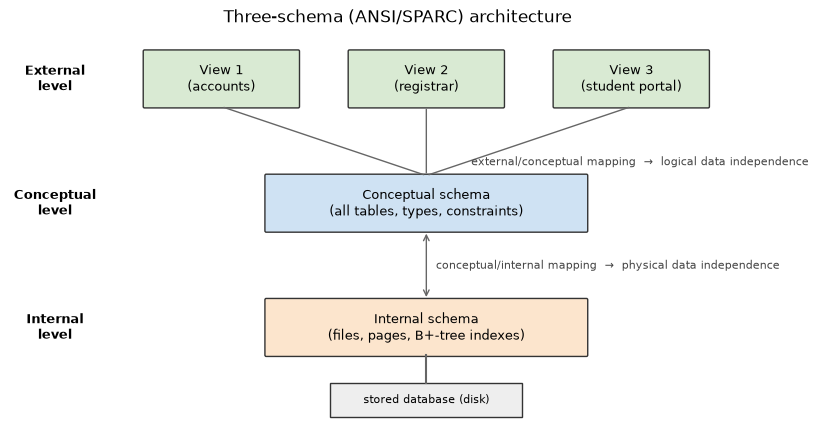

In [15]:
fig, ax = plt.subplots(figsize=(10, 5.2))
def box(x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=color, ec="#333"))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9)
for i, v in enumerate(["View 1\n(accounts)", "View 2\n(registrar)", "View 3\n(student portal)"]):
    box(0.5 + i * 3.2, 4.2, 2.4, 0.8, v, "#d9ead3")
    ax.annotate("", xy=(4.9, 3.2), xytext=(1.7 + i * 3.2, 4.2), arrowprops=dict(arrowstyle="-", color="#666"))
box(2.4, 2.4, 5.0, 0.8, "Conceptual schema\n(all tables, types, constraints)", "#cfe2f3")
box(2.4, 0.6, 5.0, 0.8, "Internal schema\n(files, pages, B+-tree indexes)", "#fce5cd")
ax.annotate("", xy=(4.9, 1.4), xytext=(4.9, 2.4), arrowprops=dict(arrowstyle="<->", color="#666"))
ax.text(5.6, 3.35, "external/conceptual mapping  →  logical data independence", fontsize=8, color="#444")
ax.text(5.05, 1.85, "conceptual/internal mapping  →  physical data independence", fontsize=8, color="#444")
for y, lab in [(4.6, "External\nlevel"), (2.8, "Conceptual\nlevel"), (1.0, "Internal\nlevel")]:
    ax.text(-0.9, y, lab, ha="center", va="center", fontsize=9, fontweight="bold")
ax.add_patch(plt.Rectangle((3.4, -0.3), 3.0, 0.5, fc="#eeeeee", ec="#333"))
ax.text(4.9, -0.05, "stored database (disk)", ha="center", va="center", fontsize=8)
ax.plot([4.9, 4.9], [0.2, 0.6], color="#666")
ax.set_xlim(-1.6, 10.5); ax.set_ylim(-0.5, 5.3); ax.axis("off")
ax.set_title("Three-schema (ANSI/SPARC) architecture")
plt.show()

### 4.4 Data independence

**Data independence** = the ability to change the schema at one level **without changing the schema (or programs) at the next higher level**.

- **Logical data independence**: change the *conceptual* schema (split a table, add a column) without changing external views or application programs. Harder to achieve.
- **Physical data independence**: change the *internal* schema (add an index, move files, change storage format) without changing the conceptual schema. Easier, and almost every relational DBMS provides it.

Let us demonstrate both in SQLite.

In [16]:
dbi = sqlite3.connect(":memory:")
dbi.executescript("""
CREATE TABLE employee(eid INT PRIMARY KEY, name TEXT, dept TEXT, phone TEXT, salary INT);
INSERT INTO employee VALUES (1,'Sana','HR','111',50000),(2,'Omar','IT','222',70000),(3,'Hina','IT','333',65000);
-- External schema used by the phone-book application:
CREATE VIEW phonebook AS SELECT name, dept, phone FROM employee;
""")
APP_QUERY = "SELECT * FROM phonebook ORDER BY name"     # the application's code never changes
before = show(dbi, APP_QUERY)
print("Before:\n", before)

# ---- Change the CONCEPTUAL schema: split employee into two tables (e.g. for security)
dbi.executescript("""
CREATE TABLE emp_public(eid INT PRIMARY KEY, name TEXT, dept TEXT, phone TEXT);
CREATE TABLE emp_salary(eid INT PRIMARY KEY REFERENCES emp_public(eid), salary INT);
INSERT INTO emp_public SELECT eid, name, dept, phone FROM employee;
INSERT INTO emp_salary SELECT eid, salary FROM employee;
DROP VIEW phonebook;
DROP TABLE employee;
-- Only the external/conceptual MAPPING (the view definition) is rewritten:
CREATE VIEW phonebook AS SELECT name, dept, phone FROM emp_public;
""")
after = show(dbi, APP_QUERY)
print("\nAfter splitting the table, the app's query still returns:\n", after)
assert before.equals(after)
print("Logical data independence: application unaffected ✔")

Before:
    name dept phone
0  Hina   IT   333
1  Omar   IT   222
2  Sana   HR   111

After splitting the table, the app's query still returns:
    name dept phone
0  Hina   IT   333
1  Omar   IT   222
2  Sana   HR   111
Logical data independence: application unaffected ✔


In [17]:
# ---- Change the INTERNAL schema: add an index. Results identical, only the access path changes.
Q = "SELECT name FROM emp_public WHERE dept = 'IT' ORDER BY name"
plan_before = dbi.execute("EXPLAIN QUERY PLAN " + Q).fetchall()
res_before = dbi.execute(Q).fetchall()
dbi.execute("CREATE INDEX idx_emp_dept ON emp_public(dept)")      # physical change
plan_after = dbi.execute("EXPLAIN QUERY PLAN " + Q).fetchall()
res_after = dbi.execute(Q).fetchall()
print("Plan before index:", [row[-1] for row in plan_before])
print("Plan after  index:", [row[-1] for row in plan_after])
assert res_before == res_after
print("Same result:", res_after, "-> physical data independence ✔")

Plan before index: ['SCAN emp_public', 'USE TEMP B-TREE FOR ORDER BY']
Plan after  index: ['SEARCH emp_public USING INDEX idx_emp_dept (dept=?)', 'USE TEMP B-TREE FOR ORDER BY']
Same result: [('Hina',), ('Omar',)] -> physical data independence ✔


**What just happened?** First we restructured the *logical* schema (one table became two) and only rewrote the view — the application query `SELECT * FROM phonebook` kept working: **logical data independence**. Then we changed the *physical* storage by adding an index: the query planner switched from `SCAN` (read every row) to `SEARCH ... USING INDEX`, but the query and its answer did not change: **physical data independence**.

> 🎓 **Exam / interview tip:** "Which data independence is harder to achieve, and why?" → **Logical**, because application programs depend heavily on the logical structure (table and column names), whereas physical details are already hidden behind the conceptual schema.

## 5. DBMS Languages: DDL, DML, DCL, TCL

> 💡 **In plain English:** a database understands four kinds of commands: ones that define tables, ones that change data, ones that give permissions, and ones that group changes into transactions.

| Language | Purpose | SQL statements | Runs in SQLite? |
|---|---|---|---|
| **DDL** – Data Definition Language | define/alter the schema; results are stored in the data dictionary | `CREATE`, `ALTER`, `DROP`, `TRUNCATE`, `RENAME`, `COMMENT` | yes (no `TRUNCATE`: use `DELETE FROM t`) |
| **DML** – Data Manipulation Language | retrieve and modify data. `SELECT` is sometimes split off as **DQL** | `SELECT`, `INSERT`, `UPDATE`, `DELETE`, `MERGE` | yes (`MERGE`: use `INSERT ... ON CONFLICT` upsert) |
| **DCL** – Data Control Language | permissions | `GRANT`, `REVOKE` | no (no user accounts) |
| **TCL** – Transaction Control Language | group statements into transactions | `BEGIN`/`START TRANSACTION`, `COMMIT`, `ROLLBACK`, `SAVEPOINT`, `RELEASE` | yes |

DMLs come in two flavours: **procedural** (the user says *how* — e.g. relational algebra, record-at-a-time navigation) and **declarative / non-procedural** (the user says *what* — SQL, relational calculus). Some books also list a **storage definition language (SDL)** and a **view definition language (VDL)** for the internal and external schemas.

In [18]:
L = sqlite3.connect(":memory:", isolation_level=None)       # autocommit; TCL statements are ours

# DDL ------------------------------------------------------------
L.execute("CREATE TABLE course(cid TEXT PRIMARY KEY, title TEXT, credits INT)")
L.execute("ALTER TABLE course ADD COLUMN dept TEXT DEFAULT 'CS'")     # change the schema
print("Columns after ALTER:", [r[1] for r in L.execute("PRAGMA table_info(course)")])

# DML ------------------------------------------------------------
L.executemany("INSERT INTO course(cid, title, credits) VALUES (?,?,?)",
              [("CS101", "Intro to Programming", 4), ("CS301", "Databases", 3), ("CS340", "AI", 3)])
L.execute("UPDATE course SET credits = 4 WHERE cid = 'CS301'")
L.execute("DELETE FROM course WHERE cid = 'CS340'")
L.execute("INSERT INTO course(cid,title,credits) VALUES ('CS301','Database Systems',4) "
          "ON CONFLICT(cid) DO UPDATE SET title = excluded.title")   # upsert ~ MERGE
print(show(L, "SELECT * FROM course"))

# TCL ------------------------------------------------------------
L.execute("BEGIN")
L.execute("INSERT INTO course VALUES ('CS999','Temp',1,'CS')")
L.execute("SAVEPOINT sp1")                                  # a named point inside the transaction
L.execute("INSERT INTO course VALUES ('CS998','Temp2',1,'CS')")
L.execute("ROLLBACK TO sp1")                                # undo only work after sp1
L.execute("COMMIT")                                         # CS999 kept, CS998 gone
print("After SAVEPOINT demo:", [r[0] for r in L.execute("SELECT cid FROM course ORDER BY cid")])

# DCL ------------------------------------------------------------
for stmt in ["GRANT SELECT ON course TO alice", "REVOKE SELECT ON course FROM alice"]:
    try:
        L.execute(stmt)
    except sqlite3.OperationalError as e:
        print(f"{stmt!r:40} -> not supported in SQLite ({e})")

Columns after ALTER: ['cid', 'title', 'credits', 'dept']
     cid                 title  credits dept
0  CS101  Intro to Programming        4   CS
1  CS301      Database Systems        4   CS
After SAVEPOINT demo: ['CS101', 'CS301', 'CS999']
'GRANT SELECT ON course TO alice'        -> not supported in SQLite (near "GRANT": syntax error)
'REVOKE SELECT ON course FROM alice'     -> not supported in SQLite (near "REVOKE": syntax error)


In a server DBMS such as PostgreSQL the DCL statements look like this (not executed here):

```sql
CREATE ROLE accounts_clerk LOGIN PASSWORD '...';
GRANT SELECT ON accounts_view TO accounts_clerk;        -- may read the view only
GRANT INSERT, UPDATE ON fee TO accounts_clerk;
REVOKE UPDATE ON fee FROM accounts_clerk;
```

> ⚠️ **Common mistake:** `TRUNCATE` is DDL (in Oracle it auto-commits and cannot be rolled back), while `DELETE` is DML. In PostgreSQL `TRUNCATE` *can* be rolled back inside a transaction — DBMSs differ, so check your vendor's docs.

## 6. Inside a DBMS: the Components

> 💡 **In plain English:** inside a DBMS, one part understands and plans your question, and another fetches data from disk, keeps busy pages in memory and protects transactions.

```
 Users:  naive users      application programmers     sophisticated users        DBA
            |                       |                          |                   |
      app interfaces          app programs  ----->    query tools           admin tools
            \______________________ | _________________________/___________________/
                                     v
 ┌────────────────────────────── QUERY PROCESSOR ─────────────────────────────┐
 │  DDL interpreter    DML compiler & organizer → query optimizer → evaluation engine │
 └───────────────────────────────────────┬──────────────────────────────────────┘
 ┌────────────────────────────── STORAGE MANAGER ─────────────────────────────┐
 │ authorization & integrity mgr │ transaction mgr (concurrency + recovery)   │
 │ file manager                  │ buffer manager (pages in RAM)              │
 └───────────────────────────────────────┬──────────────────────────────────────┘
                                     v
 Disk storage:   data files   |   indexes   |   data dictionary (catalog)   |   statistics   |   log
```

| Component | Job |
|---|---|
| **DDL interpreter** | reads DDL, records definitions in the **data dictionary** |
| **DML compiler** | translates a query into an evaluation plan of low-level operations |
| **Query optimizer** | picks the cheapest among many equivalent plans (uses statistics) |
| **Query evaluation engine** | executes the chosen plan |
| **Authorization & integrity manager** | checks permissions and constraints |
| **Transaction manager** | ensures **ACID**: **concurrency-control manager** (locks/MVCC) + **recovery manager** (log, undo/redo) |
| **File manager** | allocates disk space, manages files and pages |
| **Buffer manager** | moves disk **pages** into main-memory **frames**, decides what to evict (critical for speed, because disk ≫ RAM in latency) |

We can peek at several of them in SQLite.

In [19]:
P = sqlite3.connect(":memory:")
P.execute("CREATE TABLE big(id INTEGER PRIMARY KEY, grp INT, val REAL)")
P.executemany("INSERT INTO big(grp, val) VALUES (?,?)", [(i % 100, i * 0.5) for i in range(20000)])
P.execute("CREATE INDEX idx_grp ON big(grp)")
P.execute("ANALYZE")                                       # gather statistics for the optimizer

# Query processor: the optimizer chooses a plan
for q in ["SELECT * FROM big WHERE id = 42",               # primary-key lookup
          "SELECT * FROM big WHERE grp = 7",               # secondary index
          "SELECT AVG(val) FROM big WHERE val > 100"]:     # no index on val -> full scan
    print(f"{q:45} plan: {[r[-1] for r in P.execute('EXPLAIN QUERY PLAN ' + q)]}")

# Storage manager / file manager: data lives in fixed-size pages
page_size = P.execute("PRAGMA page_size").fetchone()[0]
page_count = P.execute("PRAGMA page_count").fetchone()[0]
print(f"\nPage size = {page_size} bytes, pages used = {page_count}  (~{page_size * page_count / 1024:.0f} KiB)")
# Buffer manager: the page cache size (negative value = size in KiB)
print("Page cache setting (PRAGMA cache_size):", P.execute("PRAGMA cache_size").fetchone()[0])
# Data dictionary: statistics collected by ANALYZE
print(show(P, "SELECT * FROM sqlite_stat1"))

SELECT * FROM big WHERE id = 42               plan: ['SEARCH big USING INTEGER PRIMARY KEY (rowid=?)']
SELECT * FROM big WHERE grp = 7               plan: ['SEARCH big USING INDEX idx_grp (grp=?)']
SELECT AVG(val) FROM big WHERE val > 100      plan: ['SCAN big']

Page size = 4096 bytes, pages used = 123  (~492 KiB)
Page cache setting (PRAGMA cache_size): -2000
   tbl      idx       stat
0  big  idx_grp  20000 200


### 6.1 Build a tiny buffer manager (LRU replacement)

The buffer manager keeps a fixed number of **frames** in RAM. When a requested page is already in a frame it is a **hit**; otherwise a **miss** (a disk read) and, if all frames are full, a **victim** page is evicted. The classic policy is **LRU (least recently used)**; DBMSs also use clock, LRU-K and MRU (MRU is better for repeated sequential scans larger than the buffer — "sequential flooding").

Worked example with 3 frames and requests `1 2 3 1 4 2`:

| request | frames after (LRU order, oldest first) | hit? | evicted |
|---|---|---|---|
| 1 | 1 | miss | – |
| 2 | 1 2 | miss | – |
| 3 | 1 2 3 | miss | – |
| 1 | 2 3 1 | **hit** | – |
| 4 | 3 1 4 | miss | 2 |
| 2 | 1 4 2 | miss | 3 |

In [20]:
class BufferManager:
    """Fixed-size page buffer with a pluggable replacement policy ('LRU' or 'MRU')."""
    def __init__(self, n_frames, policy="LRU"):
        self.n, self.policy = n_frames, policy
        self.frames = OrderedDict()          # page_id -> page data; order = recency (oldest first)
        self.hits = self.misses = 0
        self.trace = []                      # for printing a table

    def get_page(self, pid):
        evicted = None
        if pid in self.frames:               # HIT: page already in RAM
            self.hits += 1
            self.frames.move_to_end(pid)     # mark as most recently used
            hit = True
        else:                                # MISS: must read from "disk"
            self.misses += 1
            hit = False
            if len(self.frames) == self.n:   # buffer full -> choose a victim
                last = self.policy == "MRU"  # MRU evicts the newest, LRU the oldest
                evicted, _ = self.frames.popitem(last=last)
            self.frames[pid] = f"<page {pid}>"   # pretend disk read
        self.trace.append((pid, " ".join(map(str, self.frames)), "hit" if hit else "miss", evicted or "–"))
        return self.frames[pid]

bm = BufferManager(3)
for p in [1, 2, 3, 1, 4, 2]:
    bm.get_page(p)
print(pd.DataFrame(bm.trace, columns=["request", "frames (oldest→newest)", "hit?", "evicted"]))
assert [t[2] for t in bm.trace] == ["miss", "miss", "miss", "hit", "miss", "miss"]

   request frames (oldest→newest)  hit? evicted
0        1                      1  miss       –
1        2                    1 2  miss       –
2        3                  1 2 3  miss       –
3        1                  2 3 1   hit       –
4        4                  3 1 4  miss       2
5        2                  1 4 2  miss       3


In [21]:
# Sequential flooding: repeatedly scanning 4 pages with only 3 frames
scan = [1, 2, 3, 4] * 5
for policy in ["LRU", "MRU"]:
    b = BufferManager(3, policy)
    for p in scan:
        b.get_page(p)
    print(f"{policy}: hits={b.hits:2d} misses={b.misses:2d} hit ratio={b.hits / len(scan):.2f}")

LRU: hits= 0 misses=20 hit ratio=0.00
MRU: hits=11 misses= 9 hit ratio=0.55


**What just happened?** On the small trace, LRU behaved exactly like the hand-worked table. On a repeated scan of 4 pages with 3 frames, LRU always evicts the page that is needed next, so **every request misses** (hit ratio 0.00) — "sequential flooding". MRU keeps most pages and wins (hit ratio 0.55). This is why real buffer managers (e.g. PostgreSQL's clock-sweep with ring buffers for big scans) do not use pure LRU.

**Complexity:** with an `OrderedDict` (hash map + doubly linked list), each `get_page` is **O(1)** time; space is **O(F)** for F frames.

## 7. DBMS Architectures

> 💡 **In plain English:** the database can run on the same machine as the app, on its own server, behind a web server, or spread over many machines in the cloud.

### 7.1 Tiers (where the code runs)

```
 1-tier                     2-tier (client-server)             3-tier
 ┌───────────────┐          ┌────────────┐                    ┌────────────┐  presentation tier
 │ UI + logic +  │          │ client app │  UI + logic         │  browser   │  (UI only)
 │  DBMS on one  │          └─────┬──────┘                    └─────┬──────┘
 │   machine     │                │ SQL via ODBC/JDBC               │ HTTP
 └───────────────┘          ┌─────┴──────┐                    ┌─────┴──────┐  application tier
  e.g. SQLite in an app,    │ DB server  │                    │ app server │  (business logic, API)
  a DBA at the console      └────────────┘                    └─────┬──────┘
                             e.g. desktop app → Oracle             │ SQL
                                                               ┌────┴───────┐  data tier
                                                               │ DB server  │
                                                               └────────────┘
                                                                e.g. web app: React → FastAPI → PostgreSQL
```

| | 1-tier | 2-tier | 3-tier |
|---|---|---|---|
| Where is the business logic? | same place as the DB | in the client | in a middle (application) tier |
| Security | user touches the DB directly | client holds DB credentials | clients never touch the DB |
| Scalability | single machine | limited by number of DB connections | scale app servers independently |
| Typical use | embedded / local tools | departmental desktop apps | web and mobile apps, ML APIs |

Below is a tiny 3-tier system in pure Python: each tier only talks to the one below it.

In [22]:
# ---------- Data tier: only this layer runs SQL
data_tier = sqlite3.connect(":memory:")
data_tier.executescript("CREATE TABLE product(pid INT PRIMARY KEY, name TEXT, price REAL, stock INT);"
                        "INSERT INTO product VALUES (1,'Laptop',999,5),(2,'Mouse',25,0),(3,'Monitor',180,2);")

# ---------- Application tier: business rules, validation, no UI
def app_list_available(max_price):
    if max_price <= 0:                                        # validation lives here
        raise ValueError("max_price must be positive")
    rows = data_tier.execute("SELECT name, price FROM product WHERE stock > 0 AND price <= ? ORDER BY price",
                             (max_price,)).fetchall()         # parameterised: safe from SQL injection
    return [{"name": n, "price": p} for n, p in rows]         # returns plain data (like JSON)

# ---------- Presentation tier: formatting only, knows nothing about SQL
def ui_show(max_price):
    items = app_list_available(max_price)
    return "\n".join(f"  • {i['name']:<8} ${i['price']:.2f}" for i in items) or "  (nothing)"

print("Products under $500 in stock:\n" + ui_show(500))

Products under $500 in stock:
  • Monitor  $180.00


### 7.2 Where the data lives

| Architecture | Description | Pros | Cons | Examples |
|---|---|---|---|---|
| **Centralized** | one computer runs the DBMS; terminals or local apps use it | simple, consistent | single point of failure, limited scale | early mainframes, SQLite in one app |
| **Client-server** | server machine runs the DBMS; many clients connect over a network | sharing, central control | server can bottleneck | PostgreSQL, MySQL, SQL Server |
| **Parallel** | many CPUs/disks inside one system work on one query (shared-memory, shared-disk, shared-nothing) | high throughput | cost, complexity | Teradata, Oracle RAC |
| **Distributed** | data is **partitioned (sharded)** and/or **replicated** across sites connected by a network; appears as one DB | availability, locality, scale-out | distributed transactions, CAP trade-offs | Google Spanner, CockroachDB, Cassandra |
| **Cloud / DBaaS** | DBMS offered as a managed service; storage and compute often separated and elastic | no ops, pay-per-use | cost at scale, lock-in, data governance | Amazon RDS/Aurora, Google BigQuery, Azure SQL, Snowflake |

> 🎓 **Exam / interview tip:** in a distributed database, **fragmentation** (horizontal = rows split by e.g. region; vertical = columns split) and **replication** are independent choices. **Distribution transparency** means users query as if the data were in one place.

## 8. DBMS Users and Interfaces

> 💡 **In plain English:** different people use a database in different ways, from the administrator who runs it to the shop worker who only clicks buttons in an app.

| User | Who they are | How they use the DBMS |
|---|---|---|
| **Database administrator (DBA)** | central controller of the data and the DBMS | schema and storage definition, granting access, backups, performance tuning, monitoring, upgrades |
| **Database designers** | analysts who model the data | gather requirements, draw ER diagrams, choose tables and constraints (notebook 2) |
| **Naive / parametric end users** | bank tellers, shop staff, app users | run *canned transactions* through forms and apps |
| **Casual / sophisticated end users** | analysts, data scientists, managers | write ad-hoc SQL, use BI tools (Tableau, Power BI) |
| **Standalone users** | people with a personal DB | ready-made packages, spreadsheets, SQLite apps |
| **Application programmers** | software engineers | embed SQL or use APIs/ORMs in programs (Python, Java, ...) |
| **System analysts** | between users and programmers | specify canned transactions |
| Behind the scenes | DBMS designers & implementers, tool developers, operators | build and run the DBMS itself |

**Interfaces** a DBMS offers: menu-based and **form-based** interfaces, **GUIs** (pgAdmin, DBeaver, SQLite browser), **command-line** (`psql`, `sqlite3`), **APIs / drivers** (ODBC, JDBC, Python DB-API — what `sqlite3` implements), **natural-language** interfaces (today: LLM *text-to-SQL*), speech interfaces, and **DBA interfaces** for privileged commands.

## 9. Database Objects

> 💡 **In plain English:** besides tables, a database stores views, indexes, triggers and other named objects that make data easier and safer to use.

A **database object** is any named structure defined in the schema. SQLite supports tables, views, indexes and triggers natively; for the others we show the closest SQLite equivalent and the standard syntax.

| Object | Purpose | SQLite support |
|---|---|---|
| **Table** | stores data as rows and columns | ✅ |
| **View** | stored query — a *virtual table* | ✅ |
| **Index** | fast access path (usually a B-tree) | ✅ |
| **Sequence** | generates unique numbers | ⚠️ via `AUTOINCREMENT` (internal table `sqlite_sequence`) |
| **Trigger** | code run automatically on `INSERT/UPDATE/DELETE` | ✅ |
| **Stored procedure / function** | named program stored and run inside the DBMS | ❌ (use application-defined functions) |
| **Synonym** | alternative name for an object (Oracle, SQL Server) | ❌ (a view or `ATTACH ... AS` alias does a similar job) |

In [23]:
O = sqlite3.connect(":memory:")
O.executescript("""
-- TABLE (with an AUTOINCREMENT key: SQLite keeps the counter in the sqlite_sequence table)
CREATE TABLE orders(order_id INTEGER PRIMARY KEY AUTOINCREMENT, customer TEXT, amount REAL);

-- INDEX
CREATE INDEX idx_orders_customer ON orders(customer);

-- VIEW
CREATE VIEW big_orders AS SELECT * FROM orders WHERE amount >= 1000;

-- TRIGGER: keep an audit trail automatically
CREATE TABLE audit_log(log_id INTEGER PRIMARY KEY, action TEXT, order_id INT);
CREATE TRIGGER trg_orders_insert AFTER INSERT ON orders
BEGIN
    INSERT INTO audit_log(action, order_id) VALUES ('INSERT', NEW.order_id);
END;
CREATE TRIGGER trg_orders_amount BEFORE INSERT ON orders
WHEN NEW.amount <= 0
BEGIN
    SELECT RAISE(ABORT, 'amount must be positive');
END;
""")
O.executemany("INSERT INTO orders(customer, amount) VALUES (?,?)",
              [("Ali", 250.0), ("Zara", 1200.0), ("Ali", 3000.0)])
try:
    O.execute("INSERT INTO orders(customer, amount) VALUES ('Bad', -1)")
except sqlite3.IntegrityError as e:
    print("Trigger blocked the insert ->", e)

print("\nView big_orders:\n", show(O, "SELECT * FROM big_orders"))
print("\nAudit log filled by the trigger:\n", show(O, "SELECT log_id, action, order_id FROM audit_log"))
print("\nSequence counter (sqlite_sequence):\n", show(O, "SELECT * FROM sqlite_sequence"))

Trigger blocked the insert -> amount must be positive

View big_orders:
    order_id customer  amount
0         2     Zara  1200.0
1         3      Ali  3000.0

Audit log filled by the trigger:
    log_id  action  order_id
0       1  INSERT         1
1       2  INSERT         2
2       3  INSERT         3

Sequence counter (sqlite_sequence):
      name  seq
0  orders    3


In [24]:
# SEQUENCE emulation: a one-row counter table + a helper (what CREATE SEQUENCE does in PostgreSQL/Oracle)
O.execute("CREATE TABLE seq_invoice(next_val INT)")
O.execute("INSERT INTO seq_invoice VALUES (1000)")
def nextval(conn):
    """Atomically fetch-and-increment, like PostgreSQL's nextval('seq')."""
    with conn:                                                     # one transaction
        v = conn.execute("SELECT next_val FROM seq_invoice").fetchone()[0]
        conn.execute("UPDATE seq_invoice SET next_val = next_val + 1")
    return v
print("Sequence values:", [nextval(O) for _ in range(3)])

# STORED PROCEDURE / FUNCTION: SQLite cannot store one, but Python can register a function
# that SQL then calls. (In PostgreSQL: CREATE FUNCTION ... LANGUAGE plpgsql.)
def with_tax(amount, rate):
    return round(amount * (1 + rate), 2)
O.create_function("with_tax", 2, with_tax, deterministic=True)
print(show(O, "SELECT order_id, amount, with_tax(amount, 0.17) AS gross FROM orders"))

# SYNONYM: not in SQLite; a view gives another name for the same data
O.execute("CREATE VIEW ord AS SELECT * FROM orders")             # Oracle: CREATE SYNONYM ord FOR orders;
print("Rows via 'synonym' ord:", O.execute("SELECT COUNT(*) FROM ord").fetchone()[0])

print("\nAll schema objects in the catalog:")
print(show(O, "SELECT type, name, tbl_name FROM sqlite_master ORDER BY type, name"))

Sequence values: [1000, 1001, 1002]
   order_id  amount   gross
0         1   250.0   292.5
1         2  1200.0  1404.0
2         3  3000.0  3510.0
Rows via 'synonym' ord: 3

All schema objects in the catalog:
      type                 name         tbl_name
0    index  idx_orders_customer           orders
1    table            audit_log        audit_log
2    table               orders           orders
3    table          seq_invoice      seq_invoice
4    table      sqlite_sequence  sqlite_sequence
5  trigger    trg_orders_amount           orders
6  trigger    trg_orders_insert           orders
7     view           big_orders       big_orders
8     view                  ord              ord


**What just happened?** The catalog (`sqlite_master`) lists every object we created: tables, the index, two views, two triggers. The `BEFORE INSERT` trigger enforced a business rule; the `AFTER INSERT` trigger wrote an audit row for each order. Sequences, stored procedures and synonyms are standard in server DBMSs; in SQLite we used `AUTOINCREMENT`, a counter table, a Python-registered SQL function and a view.

Standard / server syntax for reference:

```sql
CREATE SEQUENCE invoice_seq START WITH 1000 INCREMENT BY 1;        -- PostgreSQL / Oracle
SELECT nextval('invoice_seq');                                      -- PostgreSQL
CREATE PROCEDURE give_raise(pct NUMERIC) LANGUAGE plpgsql AS $$
BEGIN UPDATE instructor SET salary = salary * (1 + pct/100); END $$; -- PostgreSQL 11+
CALL give_raise(5);
CREATE SYNONYM emp FOR hr.employees;                                 -- Oracle / SQL Server
```

## 10. The Impedance Mismatch

> 💡 **In plain English:** SQL hands you flat tables of rows while Python wants objects, so some translation is always needed; ORMs do that translation for you.

**Analogy:** SQL hands you a whole *bucket* of rows; your program wants to pick up *one object at a time*, and the two speak different type languages.

The **impedance mismatch** is the set of problems that arise when a **set-oriented, declarative, relational** language (SQL) is used from an **imperative, object-oriented** programming language:

| SQL / relational world | Programming-language world |
|---|---|
| relations = sets/bags of tuples | objects, lists, dicts, references |
| set-at-a-time operations | record-at-a-time loops → need **cursors** |
| SQL types (`DECIMAL`, `DATE`, `NULL`) | language types (`float`, `datetime`, `None`) |
| relationships via foreign-key *values* | relationships via *object references* |
| no inheritance | classes and inheritance |
| identity = primary key | identity = memory address |

In [25]:
from dataclasses import dataclass, field
from typing import List

@dataclass
class Course:                   # an object with a reference structure...
    cid: str
    title: str

@dataclass
class Student:
    sid: int
    name: str
    courses: List[Course] = field(default_factory=list)   # ...a list of object references

M = sqlite3.connect(":memory:")
M.executescript("""
CREATE TABLE student(sid INT PRIMARY KEY, name TEXT);
CREATE TABLE course(cid TEXT PRIMARY KEY, title TEXT);
CREATE TABLE takes(sid INT REFERENCES student, cid TEXT REFERENCES course, PRIMARY KEY(sid, cid));
INSERT INTO student VALUES (1,'Ayesha'),(2,'Bilal');
INSERT INTO course VALUES ('DB','Databases'),('AI','Artificial Intelligence');
INSERT INTO takes VALUES (1,'DB'),(1,'AI'),(2,'AI');
""")

# Manual object-relational mapping: flat rows -> nested objects, by hand
cur = M.execute("""SELECT s.sid, s.name, c.cid, c.title
                   FROM student s JOIN takes t USING(sid) JOIN course c USING(cid) ORDER BY s.sid, c.cid""")
students = {}
for sid, name, cid, title in cur:                     # the CURSOR delivers one row at a time
    st = students.setdefault(sid, Student(sid, name))
    st.courses.append(Course(cid, title))
for st in students.values():
    print(st)

# Going back (object -> rows) is also manual: we must flatten references into key values
new = Student(3, "Chen", [Course("DB", "Databases")])
M.execute("INSERT INTO student VALUES (?,?)", (new.sid, new.name))
M.executemany("INSERT INTO takes VALUES (?,?)", [(new.sid, c.cid) for c in new.courses])
print("\nRows in takes now:", M.execute("SELECT COUNT(*) FROM takes").fetchone()[0])

Student(sid=1, name='Ayesha', courses=[Course(cid='AI', title='Artificial Intelligence'), Course(cid='DB', title='Databases')])
Student(sid=2, name='Bilal', courses=[Course(cid='AI', title='Artificial Intelligence')])

Rows in takes now: 4


**What just happened?** One SQL query returned *flat* rows where Ayesha appears twice; we needed a loop over a **cursor** and a dictionary to rebuild nested `Student` objects, and the reverse direction needed flattening references back into key values. Doing this by hand for every class is tedious and error-prone.

**Solutions to the impedance mismatch:**
- **Embedded SQL / cursors** (`EXEC SQL ...` in C/COBOL, JDBC/DB-API cursors).
- **Database programming languages** inside the DBMS (PL/SQL, PL/pgSQL, T-SQL).
- **Object-Relational Mappers (ORMs)** such as SQLAlchemy, Django ORM, Hibernate: classes map to tables, attributes to columns, references to foreign keys — see the repo's [ORM notebook](../04_orm/01_orm.ipynb) (including the famous **N+1 query problem**, which is the impedance mismatch biting back).
- **Object-oriented / document databases**, which store objects or JSON directly.

## 11. Popular DBMSs Today (2026)

> 💡 **In plain English:** a quick tour of the database products people actually use today and what each one is good at.

| DBMS | Type | Licence | Typical use |
|---|---|---|---|
| **Oracle Database** | relational (multi-model) | commercial | large enterprises, banking, ERP |
| **MySQL** / **MariaDB** | relational | open source (GPL) / commercial editions | web applications (LAMP stack) |
| **Microsoft SQL Server** | relational | commercial | Windows/.NET enterprise systems |
| **PostgreSQL** | object-relational | open source (PostgreSQL licence) | general purpose; extensions such as PostGIS, `pgvector` for AI embeddings |
| **SQLite** | relational, embedded | public domain | phones, browsers, desktop apps, this notebook |
| **IBM Db2** | relational | commercial | mainframes, enterprise |
| **MongoDB** | document (NoSQL) | SSPL / commercial | flexible-schema applications |
| **Redis** | key-value, in-memory | source-available (Redis 8 adds AGPL option) | caching, sessions, queues |
| **Apache Cassandra** | wide-column (NoSQL) | open source (Apache) | write-heavy, globally distributed data |
| **Neo4j** | graph | community (GPL) / commercial | relationships, fraud detection, knowledge graphs |
| **Elasticsearch / OpenSearch** | search engine (document) | mixed / Apache | full-text search, logs |
| **Snowflake**, **Google BigQuery**, **Amazon Redshift**, **Databricks** | cloud analytical (columnar) | commercial services | data warehouses / lakehouses |
| **DuckDB** | analytical, embedded, columnar | open source (MIT) | "SQLite for analytics", data science |
| **Pinecone, Milvus, Weaviate, Qdrant** | vector | mixed | similarity search for RAG |

The [DB-Engines ranking](https://db-engines.com/en/ranking) tracks popularity monthly; for years the top five have been Oracle, MySQL, Microsoft SQL Server, PostgreSQL and MongoDB, with PostgreSQL rising steadily. In developer surveys (e.g. Stack Overflow's), PostgreSQL has been the most used database for several years running.

More on these families: [NoSQL](../02_nosql/01_nosql_databases.ipynb), [vector databases](../03_vector_db/01_vector_databases.ipynb), [graph databases](../07_graph_databases/01_graph_databases.ipynb), [time-series databases](../08_time_series_databases/01_time_series_databases.ipynb), [DuckDB](../../02_Data_Analysis/10_duckdb.ipynb).

## 🔗 How this connects to modern AI

> 💡 **In plain English:** AI systems keep their data, features, experiment results and even embeddings in databases, so these ideas show up everywhere in AI.

- **Every ML system is a DBMS client.** Training data, feature stores, experiment metadata (MLflow uses a relational backend) and prediction logs all live in DBMSs — see [Databases in AI](../05_db_in_ai/01_databases_in_ai.ipynb) and [Relational DB design for ML](../../22_ML_System_Design/03_relational_db_design.ipynb).
- **Data independence → feature pipelines.** Views and stable external schemas let data engineers change storage (row store → Parquet/columnar lakehouse) without breaking model-training code ([Data Engineering](../06_data_engineering/01_data_engineering.ipynb)).
- **Natural-language interfaces are back.** LLM *text-to-SQL* agents are a modern "natural-language DBMS interface"; they work best when given the **schema from the catalog** (exactly what `sqlite_master` shows) and when restricted to read-only **views** — a security lesson from section 2.6.
- **Transactions matter for agents.** An AI agent that books a flight and charges a card needs atomicity just like our bank transfer ([Agents](../../10_Agents)).
- **Vector search inside DBMSs.** PostgreSQL + `pgvector`, and vector indexes in Oracle, MongoDB and others, bring embeddings into the classic DBMS architecture: one more index type managed by the same query processor and storage manager ([Vector DBs](../03_vector_db/01_vector_databases.ipynb)).
- **Buffer management ↔ KV-cache.** LLM inference servers (e.g. vLLM's *PagedAttention*) manage GPU memory in fixed-size pages with eviction policies — the same idea as a DBMS buffer manager.

In [26]:
# Clean up temporary files and connections
for c in [db, bank, uni, dbi, L, P, O, M, data_tier]:
    c.close()
shutil.rmtree(WORKDIR)
print("Temporary folder removed:", not os.path.exists(WORKDIR))

Temporary folder removed: True


## Recap

> 💡 **In plain English:** the key ideas in a few bullets, then practice problems to check you really understood them.

- **Data** are raw facts; **information** is processed, meaningful data. A **DBMS** defines, constructs, manipulates, shares and protects a database.
- File-processing systems suffer from **redundancy, inconsistency, difficult access, isolation, integrity, atomicity, concurrency and security** problems — you saw each one break and SQLite fix it.
- A DBMS costs money, skills and overhead, but gives controlled redundancy, integrity, security, recovery, concurrency, declarative queries and **data independence**.
- **Schema** = structure (stable, in the catalog); **instance** = data at a moment.
- Data models: hierarchical, network, relational, object(-relational), document/NoSQL; the ER model is used for conceptual design.
- **Three-schema architecture**: external, conceptual, internal levels with mappings → **logical** (harder) and **physical** (easier) data independence.
- Languages: **DDL** (schema), **DML** (data; procedural vs declarative), **DCL** (`GRANT/REVOKE`), **TCL** (`COMMIT/ROLLBACK/SAVEPOINT`).
- Components: **query processor** (DDL interpreter, DML compiler, optimizer, evaluation engine) and **storage manager** (authorization/integrity, transaction, file, **buffer** managers).
- Architectures: 1/2/3-tier; centralized, client-server, parallel, distributed, cloud.
- Users: DBA, designers, end users (naive, sophisticated, standalone), application programmers.
- The **impedance mismatch** between set-oriented SQL and object-oriented code is handled with cursors, DB languages or **ORMs**.

## Practice problems

**1. (Easy)** Classify as *data* or *information*: (a) `"2026-10-27"`; (b) "sales grew 12% this quarter"; (c) a column of 10 000 transaction amounts; (d) "the busiest hour is 18:00".
<details><summary>Show solution</summary>

(a) data, (b) information, (c) data, (d) information — (b) and (d) are processed and put in context.
</details>

**2. (Easy)** Which file-system problem does each situation show? (i) a customer's phone is different in the CRM file and the billing file; (ii) an order was saved but the stock was never decreased after a crash; (iii) two agents sold the last seat on a flight.
<details><summary>Show solution</summary>

(i) data **inconsistency** (caused by redundancy); (ii) **atomicity** problem; (iii) **concurrent-access anomaly** (lost update / double booking).
</details>

**3. (Medium)** A DBA moves a table to a faster SSD and adds a B-tree index; separately, a designer splits `customer` into `customer` and `customer_address` and rewrites the views. Which kind of data independence does each change rely on, and which level's schema changed?
<details><summary>Show solution</summary>

The SSD move + index changes the **internal schema**; programs are protected by **physical data independence** (the conceptual/internal mapping absorbs it). The table split changes the **conceptual schema**; views/programs survive thanks to **logical data independence** (the external/conceptual mapping — the view definitions — absorbs it).
</details>

**4. (Medium)** Classify each statement as DDL, DML, DCL or TCL: `CREATE INDEX`, `SAVEPOINT a`, `REVOKE INSERT ON t FROM u`, `MERGE INTO`, `TRUNCATE TABLE t`, `SELECT`, `ALTER TABLE`.
<details><summary>Show solution</summary>

`CREATE INDEX` DDL; `SAVEPOINT` TCL; `REVOKE` DCL; `MERGE` DML; `TRUNCATE` DDL; `SELECT` DML (or DQL); `ALTER TABLE` DDL.
</details>

**5. (Medium, coding)** Use the `BufferManager` class to compute LRU and MRU hit counts for the trace `[1, 2, 3, 4, 1, 2, 5, 1, 2, 3, 4, 5]` with 3 frames.
<details><summary>Show solution</summary>

```python
trace = [1, 2, 3, 4, 1, 2, 5, 1, 2, 3, 4, 5]
for pol in ["LRU", "MRU"]:
    b = BufferManager(3, pol)
    for p in trace: b.get_page(p)
    print(pol, b.hits, b.misses)
# LRU 2 10
# MRU 5 7
```
LRU: misses on 1,2,3,4,1,2,5, hits on the next 1,2, then misses on 3,4,5 → **2 hits**. MRU evicts the newest page, so old pages survive: hits on 1, 2 (after 4), 1 (after 5), 4, 5 → **5 hits**.
</details>

**6. (Medium, coding)** Write a SQLite trigger that prevents any `UPDATE` that lowers an account's balance below zero, and show it rejecting a bad update.
<details><summary>Show solution</summary>

```python
c = sqlite3.connect(":memory:")
c.executescript("""
CREATE TABLE account(acct TEXT PRIMARY KEY, balance INT);
INSERT INTO account VALUES ('A', 100);
CREATE TRIGGER no_overdraft BEFORE UPDATE OF balance ON account
WHEN NEW.balance < 0
BEGIN SELECT RAISE(ABORT, 'overdraft not allowed'); END;
""")
try:
    c.execute("UPDATE account SET balance = balance - 500 WHERE acct='A'")
except sqlite3.IntegrityError as e:
    print(e)        # overdraft not allowed
```
</details>

**7. (Hard, conceptual)** Explain why a 3-tier architecture is preferred for a public ML prediction API instead of letting the mobile app connect to PostgreSQL directly (2-tier). Give at least three reasons.
<details><summary>Show solution</summary>

(1) **Security**: database credentials would have to ship inside the app; in 3-tier only the app server holds them and exposes a narrow API. (2) **Scalability**: thousands of phones would each open DB connections (expensive); app servers pool a few connections and can be scaled horizontally. (3) **Business logic in one place**: validation, model inference and rate-limiting live on the server and can be updated without updating every client. (4) **Data independence for clients**: the schema can change while the API contract stays stable.
</details>

**8. (Hard, coding)** Demonstrate the *lost update* inside SQLite itself by using two connections that each `SELECT` the balance first and then `UPDATE` with a value computed in Python, *without* `BEGIN IMMEDIATE`. Then fix it with a single atomic `UPDATE ... SET balance = balance - ?`.
<details><summary>Show solution</summary>

```python
import tempfile, os
d = tempfile.mkdtemp(); f = os.path.join(d, "x.db")
a = sqlite3.connect(f, isolation_level=None); b = sqlite3.connect(f, isolation_level=None)
a.executescript("CREATE TABLE acc(id INT PRIMARY KEY, bal INT); INSERT INTO acc VALUES (1, 100);")
va = a.execute("SELECT bal FROM acc").fetchone()[0]       # both read 100 (autocommit reads)
vb = b.execute("SELECT bal FROM acc").fetchone()[0]
a.execute("UPDATE acc SET bal=? WHERE id=1", (va - 10,))
b.execute("UPDATE acc SET bal=? WHERE id=1", (vb - 20,))
print(a.execute("SELECT bal FROM acc").fetchone()[0])      # 80, not 70: lost update
a.execute("UPDATE acc SET bal=100")
a.execute("UPDATE acc SET bal = bal - 10"); b.execute("UPDATE acc SET bal = bal - 20")
print(a.execute("SELECT bal FROM acc").fetchone()[0])      # 70: correct
a.close(); b.close(); import shutil; shutil.rmtree(d)
```
The DBMS can only protect you if the read and the write are in the **same transaction** (or the same statement): reads done in separate autocommit statements let the application reintroduce the anomaly.
</details>

## Further reading

- Silberschatz, Korth & Sudarshan, *Database System Concepts*, 7th ed., **Chapter 1** (Introduction) and Chapter 20 (Database-System Architectures).
- Elmasri & Navathe, *Fundamentals of Database Systems*, 7th ed., **Chapters 1–2** (Databases and Database Users; Database System Concepts and Architecture).
- Ramakrishnan & Gehrke, *Database Management Systems*, 3rd ed., Chapter 1 and Chapter 9 (buffer management).
- GeeksforGeeks, [DBMS Tutorial](https://www.geeksforgeeks.org/dbms/dbms/) — Introduction & Architecture sections.
- CMU 15-445/645 *Intro to Database Systems* (Andy Pavlo), free lectures on YouTube — lectures on storage and buffer pools.

## Next notebook

➡️ [02 — The ER Model and Enhanced ER](02_er_model_and_eer.ipynb): how designers turn requirements into a picture of entities and relationships, and then into tables.